In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report


header = ['comment_id', 'text', 'date', 'song', 'artist', 'kendrick_score', 'drake_score']
dataset = pd.read_csv(filepath_or_buffer='./cleaned_comments/cleaned_comments.csv',  delimiter=',', names=header, skiprows=1)
dataset

,comment_id,text,date,song,artist,kendrick_score,drake_score
0,Ugzc5Srhx8p6qzdSjvB4AaABAg,Kendrick responded so fast I didnt know Drake ...,2024-05-04 12:59:37+00:00,Family_Matters,BagOnly_Drake,2,-1
1,UgxGl-mJYHo4mzjNy0R4AaABAg,Beat switches each time a different ghost writ...,2024-05-04 08:41:23+00:00,Family_Matters,BagOnly_Drake,0,-2
2,Ugw8sI-rRjgKXTUCBFV4AaABAg,Kendrick had a diss ready for this song not ev...,2024-05-04 05:18:35+00:00,Family_Matters,BagOnly_Drake,2,0
3,UgzkG6vRyh2O9FOlnJR4AaABAg,Imagine sitting down in a group and writing th...,2024-05-04 17:04:41+00:00,Family_Matters,BagOnly_Drake,1,-1
4,UgyRU5sH2RugrPSNal94AaABAg,ngl Drake's melody is fire\n\nbut Kendrick's l...,2024-05-05 06:28:06+00:00,Family_Matters,BagOnly_Drake,3,2
...,...,...,...,...,...,...,...
5693,Ugy_pfO-XFQhO5gGBA94AaABAg,"''I agree'' with you, this track is so deep th...",2024-05-05 10:59:39+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,0
5694,UgwKaRbSQ7CT8Id9UlJ4AaABAg,"It's like y'all came in expecting a comedy, wa...",2024-05-04 21:19:33+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,-3
5695,UgwKuRsl6mRT319BxZB4AaABAg,Kendrick gave you all the bars and metaphors y...,2024-05-05 05:00:26+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,0
5696,UgxGzHrFJUiB4cJv-7t4AaABAg,Never thought I would think this channel would...,2024-05-04 22:54:04+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,2,-2


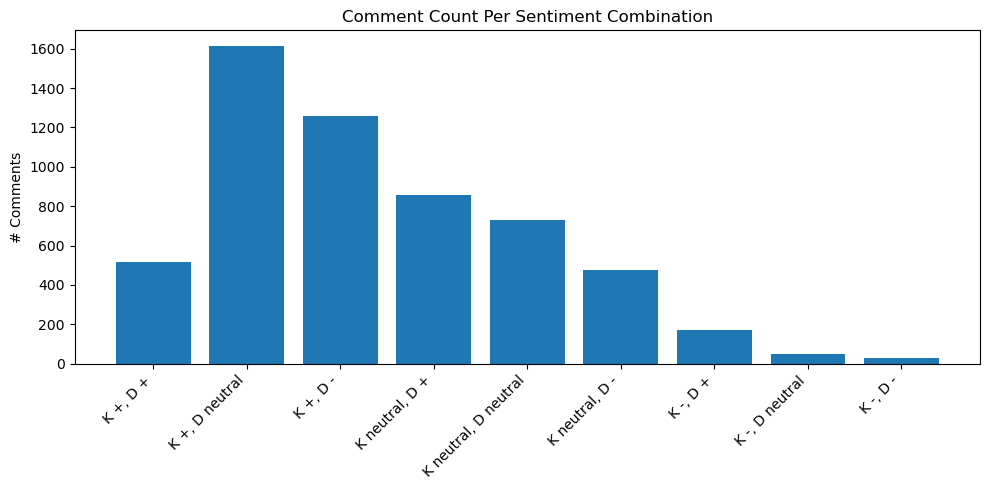

In [8]:
#pulling together the same labeled data as the naive bayes -- I think trying to 
#fit how I originally wanted to (to predict each combination) is again slicing too
#fine. so we'll see how the coarser method works

signs = {1: '+', 0: 'neutral', -1: '-'}

k_signs = np.sign(dataset['kendrick_score']).astype(int).map(signs)
d_signs = np.sign(dataset['drake_score']).astype(int).map(signs)

youtube_comment_texts = dataset['text'].values
youtube_comment_labels = ('K ' + k_signs + ', D ' + d_signs).values

order = ['+', 'neutral', '-']
all_labels = [f"K {k}, D {d}" for k in order for d in order]

counts = pd.Series(youtube_comment_labels).value_counts().reindex(all_labels, fill_value=0)

plt.figure(figsize=(10, 5))
plt.bar(counts.index, counts.values)
plt.xticks(rotation=45, ha='right')
plt.ylabel('# Comments')
plt.title('Comment Count Per Sentiment Combination')
plt.tight_layout()
plt.show()

how does the tree size change with tree depth?

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50]
1 0.374 0.389
2 0.376 0.392
3 0.394 0.414
4 0.407 0.424
5 0.42 0.436
6 0.43 0.44
7 0.441 0.442
8 0.455 0.447
9 0.466 0.453
10 0.481 0.458
11 0.495 0.453
12 0.506 0.456
13 0.522 0.459
14 0.531 0.463
15 0.542 0.459
16 0.556 0.467
17 0.567 0.474
18 0.583 0.465
19 0.594 0.466
20 0.611 0.457
21 0.624 0.467
22 0.632 0.458
23 0.649 0.453
24 0.659 0.457
25 0.669 0.449
26 0.678 0.466
27 0.686 0.468
28 0.692 0.474
29 0.697 0.471
30 0.706 0.466
31 0.714 0.459
32 0.722 0.454
33 0.73 0.456
34 0.736 0.469
35 0.744 0.463
36 0.751 0.459
37 0.76 0.464
38 0.763 0.445
39 0.767 0.459
40 0.773 0.471
41 0.777 0.465
42 0.785 0.46
43 0.788 0.457
44 0.793 0.464
45 0.797 0.473
46 0.801 0.474
47 0.806 0.466
48 0.811 0.474
49 0.816 0.467
50 0.82 0.472


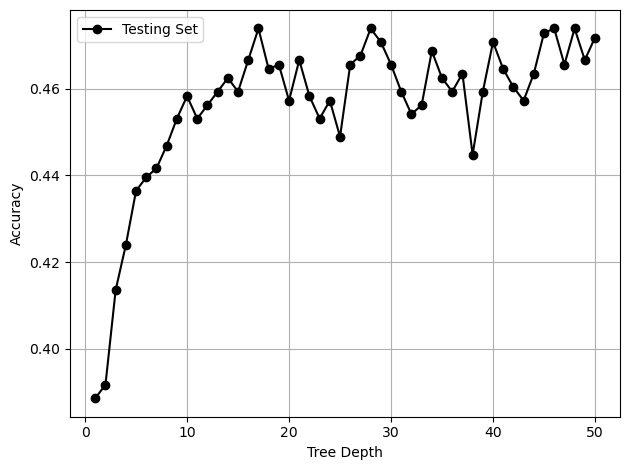

In [ ]:


X_train, X_test, y_train, y_test = train_test_split(youtube_comment_texts,
                                                    youtube_comment_labels,
                                                    test_size=0.1684,
                                                    random_state=112)

#Creating the model
vec = CountVectorizer()
X = vec.fit_transform(X_train)
X_test_vec = vec.transform(X_test)

#looking at the accuract with depth
depths = np.linspace(start=1, stop=50, num=50, endpoint=True, dtype=int)
# depths = np.append(depths, 'None')
print(depths)
accuracies_test = []
accuracies_train = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=5124)
    tree.fit(X, y_train)
    accuracies_train.append(tree.score(X, y_train))
    accuracies_test.append(tree.score(X_test_vec, y_test))
    print(d, round(tree.score(X, y_train), 3),
            round(tree.score(X_test_vec, y_test), 3))

plt.figure()
plt.plot(depths, accuracies_test, marker='o', ls='-', c='black',
         label='Testing Set')
# plt.plot(depths, accuracies_train,  marker='o', ls='-', c='blue', 
#          label='Training Set')
plt.ylabel("Accuracy")
plt.xlabel("Tree Depth")
# plt.title("")
plt.legend(loc='best')
plt.tight_layout()
plt.grid(True)
plt.show()

In [37]:
idx = np.argmax(accuracies_test)
print(f'Accuracy is highest when the tree depth is {(depths[idx])} at an accuracy of {accuracies_test[idx]*100:.2f}%')

Accuracy is highest when the tree depth is 17 at an accuracy of 47.40%


how does accuracy change with data split percentage

10 0.491 0.351
10 0.49 0.395
10 0.491 0.412
10 0.491 0.415
10 0.494 0.4
10 0.494 0.399
10 0.493 0.37
10 0.495 0.388
10 0.492 0.406
10 0.492 0.408
10 0.49 0.397
10 0.492 0.399
10 0.491 0.396
10 0.491 0.403
10 0.492 0.409
10 0.491 0.41
10 0.494 0.399
10 0.493 0.4
10 0.491 0.414
10 0.49 0.408
10 0.491 0.405
10 0.492 0.405
10 0.495 0.419
10 0.495 0.411
10 0.49 0.421
10 0.491 0.429
10 0.493 0.43
10 0.493 0.425
10 0.49 0.442
10 0.49 0.44
10 0.485 0.45
10 0.483 0.451
10 0.481 0.458
10 0.481 0.452
10 0.481 0.443
10 0.481 0.433
10 0.481 0.435
10 0.48 0.437
10 0.48 0.438
10 0.482 0.441
10 0.486 0.44
10 0.484 0.443
10 0.486 0.446
10 0.487 0.44
10 0.488 0.448
10 0.491 0.443
10 0.483 0.443
10 0.49 0.445
10 0.483 0.444
10 0.48 0.441
10 0.482 0.436
10 0.487 0.431
10 0.487 0.432
10 0.486 0.427
10 0.487 0.432
10 0.486 0.433
10 0.487 0.431
10 0.492 0.426
10 0.493 0.432
10 0.491 0.427
10 0.49 0.428
10 0.49 0.426
10 0.492 0.426
10 0.491 0.429
10 0.496 0.429
10 0.493 0.428
10 0.494 0.422
10 0.496 0.425
10 

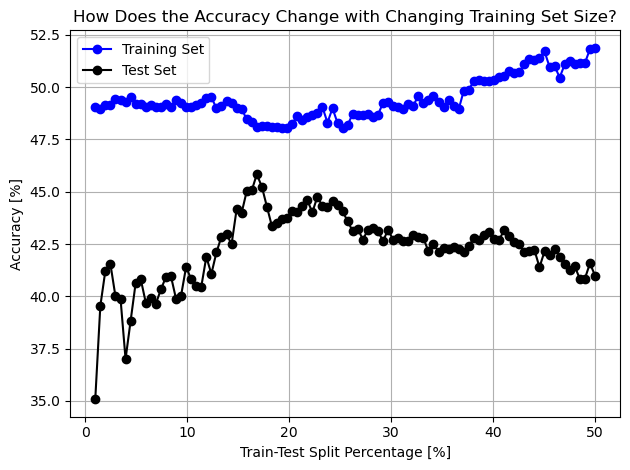

In [33]:
#how does the accuracy change with test size? what is the optimal test size?
ttsplit_percentage = np.linspace(0.01, 0.5, num=100, endpoint=True)

accuracies_test = []
accuracies_train = []
for split_percentage in ttsplit_percentage:
    #extracting 5% of the comments for the testing set (285)
    X_train, X_test, y_train, y_test = train_test_split(
        youtube_comment_texts,
        youtube_comment_labels,
        test_size=split_percentage,
        random_state=112
    )


    vec = CountVectorizer()
    X = vec.fit_transform(X_train)
    X_test_vec = vec.transform(X_test)

    depth = 10
    tree = DecisionTreeClassifier(max_depth=depth, random_state=5124)
    tree.fit(X, y_train)
    accuracies_train.append(tree.score(X, y_train))
    accuracies_test.append(tree.score(X_test_vec, y_test))
    print(depth, round(tree.score(X, y_train), 3),
            round(tree.score(X_test_vec, y_test), 3))

accuracies_train = np.asarray(accuracies_train)
accuracies_test = np.asarray(accuracies_test)

plt.figure()
plt.plot(ttsplit_percentage*100, accuracies_train*100, marker='o', ls='-', c='blue', label='Training Set')
plt.plot(ttsplit_percentage*100, accuracies_test*100, marker='o', ls='-', c='black', label='Test Set')
plt.ylabel("Accuracy [%]")
plt.xlabel("Train-Test Split Percentage [%]")
plt.title("How Does the Accuracy Change with Changing Training Set Size?")
plt.tight_layout()
plt.legend()
plt.grid(True)
plt.show()


In [31]:
idx = np.argmax(accuracies_test)
print(f'Accuracy is highest when the test data is {(ttsplit_percentage[idx]*100):.2f}% at an accuracy of {accuracies_test[idx]*100:.2f}%')

Accuracy is highest when the test data is 16.84% at an accuracy of 45.83%


PLotting the decision trees

17 0.567 0.474


[Text(0.5, 0.9, 'drake <= 0.5\ngini = 0.817\nsamples = 4738\nvalue = [416.0, 1066.0, 1324.0, 150.0, 27.0, 42.0, 708.0, 395.0\n610.0]\nclass = K +, D neutral'),
 Text(0.25, 0.7, 'kendrick <= 0.5\ngini = 0.783\nsamples = 3418\nvalue = [255.0, 551.0, 1256.0, 65.0, 21.0, 41.0, 464.0, 195.0\n570.0]\nclass = K +, D neutral'),
 Text(0.375, 0.8, 'True  '),
 Text(0.125, 0.5, 'beef <= 0.5\ngini = 0.801\nsamples = 2722\nvalue = [218.0, 373.0, 869.0, 39.0, 18.0, 23.0, 452.0, 188.0\n542.0]\nclass = K +, D neutral'),
 Text(0.0625, 0.3, 'rights <= 0.5\ngini = 0.794\nsamples = 2612\nvalue = [169.0, 349.0, 856.0, 37.0, 12.0, 23.0, 446.0, 188.0\n532.0]\nclass = K +, D neutral'),
 Text(0.03125, 0.1, '\n  (...)  \n'),
 Text(0.09375, 0.1, '\n  (...)  \n'),
 Text(0.1875, 0.3, 'the <= 1.5\ngini = 0.725\nsamples = 110\nvalue = [49, 24, 13, 2, 6, 0, 6, 0, 10]\nclass = K +, D +'),
 Text(0.15625, 0.1, '\n  (...)  \n'),
 Text(0.21875, 0.1, '\n  (...)  \n'),
 Text(0.375, 0.5, 'opened <= 0.5\ngini = 0.618\nsamples 

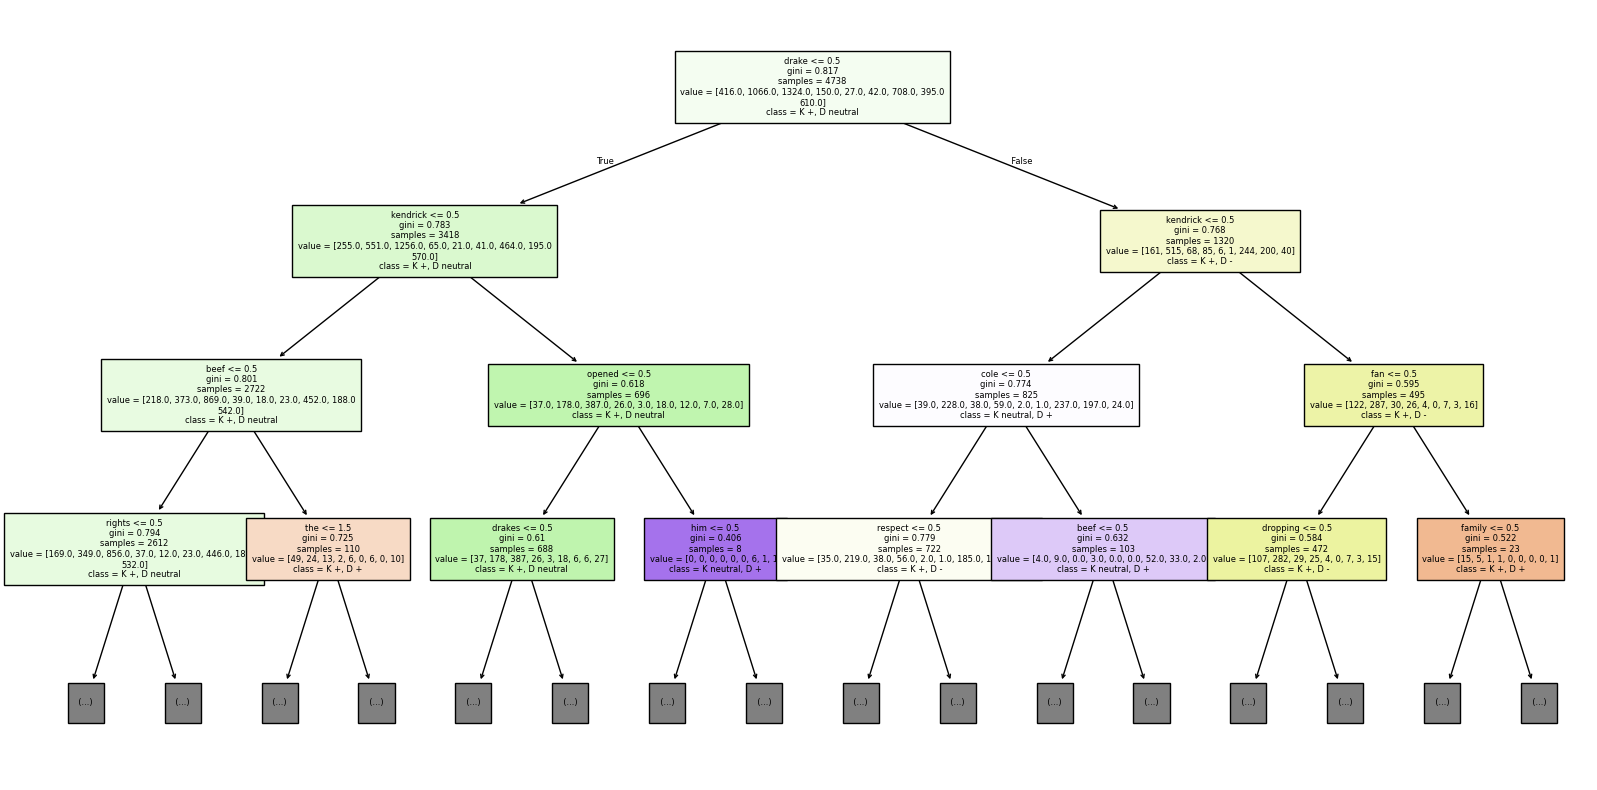

In [49]:
#plotting shorter depth trees for different metrics - starting with a visualization
from sklearn.tree import plot_tree

splitpercentage = 0.1684
X_train, X_test, y_train, y_test = train_test_split(youtube_comment_texts,
                                                    youtube_comment_labels,
                                                    test_size=splitpercentage,
                                                    random_state=112)

#Creating the model
vec = CountVectorizer()
X = vec.fit_transform(X_train)
X_test_vec = vec.transform(X_test)

#looking at the accuract with depth
depth = 17
tree = DecisionTreeClassifier(max_depth=depth, random_state=5124)
tree.fit(X, y_train)

print(depth, round(tree.score(X, y_train), 3),
            round(tree.score(X_test_vec, y_test), 3))

plt.figure(figsize=(20, 10))
plot_tree(tree,
    feature_names=vec.get_feature_names_out(),
    class_names=tree.classes_,
    max_depth=3,
    filled=True,
    fontsize=6,
)

17 0.617 0.441


[Text(0.5, 0.9, 'drake <= 0.5\nentropy = 2.656\nsamples = 4738\nvalue = [416.0, 1066.0, 1324.0, 150.0, 27.0, 42.0, 708.0, 395.0\n610.0]\nclass = K +, D neutral'),
 Text(0.25, 0.7, 'kendrick <= 0.5\nentropy = 2.523\nsamples = 3418\nvalue = [255.0, 551.0, 1256.0, 65.0, 21.0, 41.0, 464.0, 195.0\n570.0]\nclass = K +, D neutral'),
 Text(0.375, 0.8, 'True  '),
 Text(0.125, 0.5, 'beef <= 0.5\nentropy = 2.564\nsamples = 2722\nvalue = [218.0, 373.0, 869.0, 39.0, 18.0, 23.0, 452.0, 188.0\n542.0]\nclass = K +, D neutral'),
 Text(0.0625, 0.3, 'this <= 0.5\nentropy = 2.53\nsamples = 2612\nvalue = [169.0, 349.0, 856.0, 37.0, 12.0, 23.0, 446.0, 188.0\n532.0]\nclass = K +, D neutral'),
 Text(0.03125, 0.1, '\n  (...)  \n'),
 Text(0.09375, 0.1, '\n  (...)  \n'),
 Text(0.1875, 0.3, 'the <= 1.5\nentropy = 2.24\nsamples = 110\nvalue = [49, 24, 13, 2, 6, 0, 6, 0, 10]\nclass = K +, D +'),
 Text(0.15625, 0.1, '\n  (...)  \n'),
 Text(0.21875, 0.1, '\n  (...)  \n'),
 Text(0.375, 0.5, 'opened <= 0.5\nentropy = 1

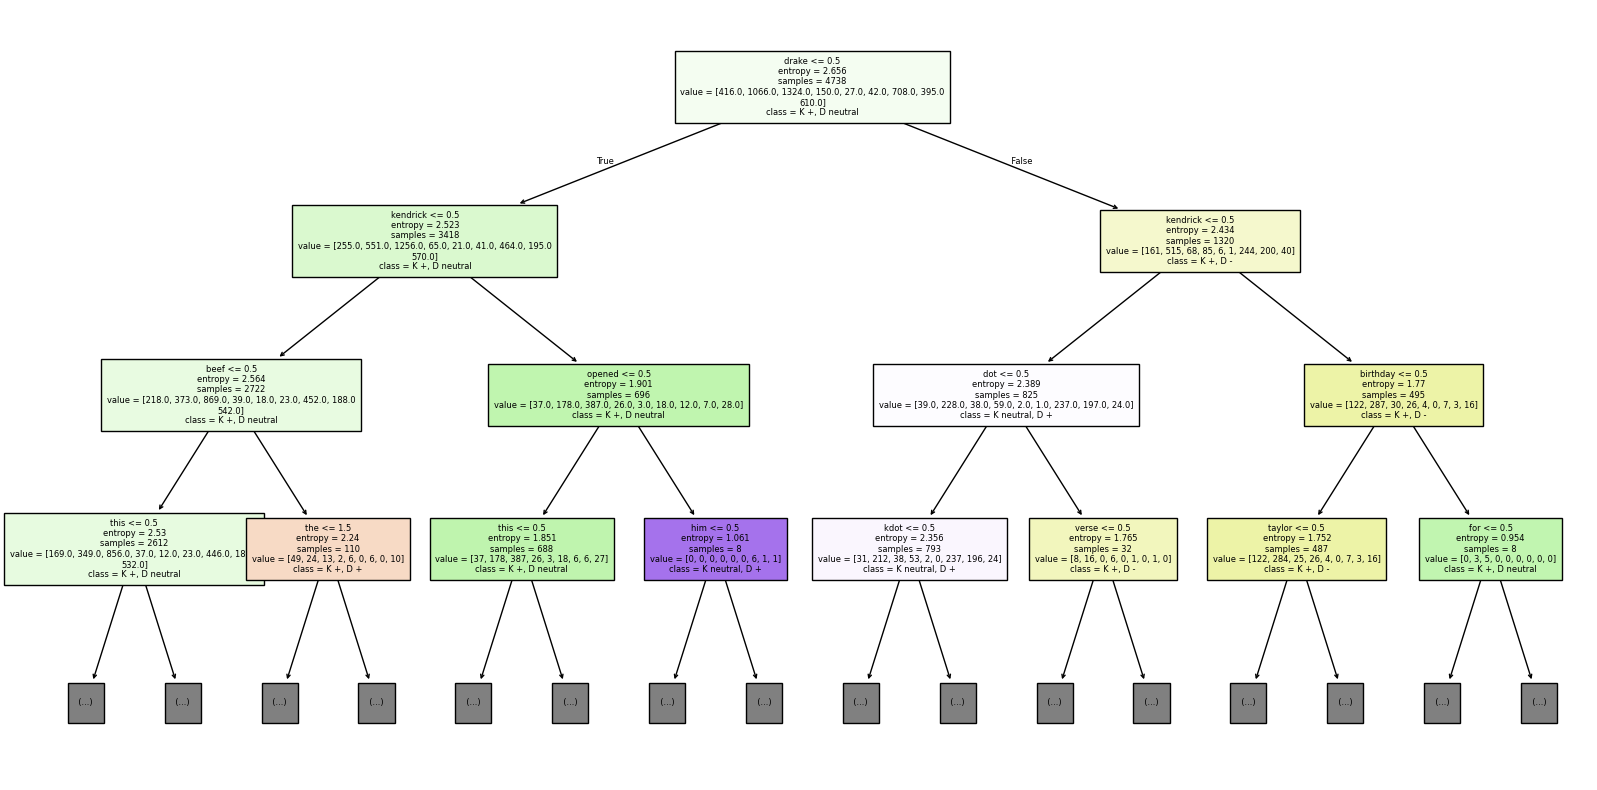

In [50]:
#plotting shorter depth trees for different metrics - starting with a visualization
from sklearn.tree import plot_tree

splitpercentage = 0.1684
X_train, X_test, y_train, y_test = train_test_split(youtube_comment_texts,
                                                    youtube_comment_labels,
                                                    test_size=splitpercentage,
                                                    random_state=112)

#Creating the model
vec = CountVectorizer()
X = vec.fit_transform(X_train)
X_test_vec = vec.transform(X_test)

#looking at the accuract with depth
depth = 17
tree = DecisionTreeClassifier(max_depth=depth, random_state=5124, criterion='entropy')
tree.fit(X, y_train)

print(depth, round(tree.score(X, y_train), 3),
            round(tree.score(X_test_vec, y_test), 3))

plt.figure(figsize=(20, 10))
plot_tree(tree,
    feature_names=vec.get_feature_names_out(),
    class_names=tree.classes_,
    max_depth=3,
    filled=True,
    fontsize=6,
)

In [57]:
train_df = pd.DataFrame({'text': X_train, 'label': y_train, 'set': 'train'})
test_df = pd.DataFrame({'text': X_test, 'label': y_test, 'set': 'test'})

train_df

,text,label,set
0,This shit hits so much harder now,"K +, D neutral",train
1,Nas “no idea is original” rapped on that sample.,"K neutral, D neutral",train
2,I swear I missed this type of vibe right here....,"K +, D neutral",train
3,Meet the grahams has to be my favorite Kendric...,"K +, D neutral",train
4,Bro switched the flow so many times,"K +, D neutral",train
...,...,...,...
4733,A minor😭....someone said that this bars are pu...,"K +, D -",train
4734,I dont think ive ever seen Knox's face stuck l...,"K neutral, D -",train
4735,"oh brother, get a load of this guy","K neutral, D -",train
4736,Kendrick d-riders taking over the comment sect...,"K -, D neutral",train


In [58]:
test_df

,text,label,set
0,George is definitely reaching this episode,"K neutral, D neutral",test
1,You gotta run it back 😂😂 drake -family matters...,"K +, D +",test
2,"This Drake diss is hard, best heard out of him...","K neutral, D +",test
3,Drake still got clever lines and punchlines to...,"K neutral, D +",test
4,This aged terribly,"K neutral, D -",test
...,...,...,...
955,Kendrick 4 - 0,"K +, D neutral",test
956,I think the last song I did personnally listen...,"K -, D +",test
957,Not him crushing the MAAD city van 😮,"K +, D -",test
958,Drake is cooked bro😭 I don’t think there’s any...,"K +, D -",test


Confusion matrix for the tree w/ best accuracy

17 0.567 0.474


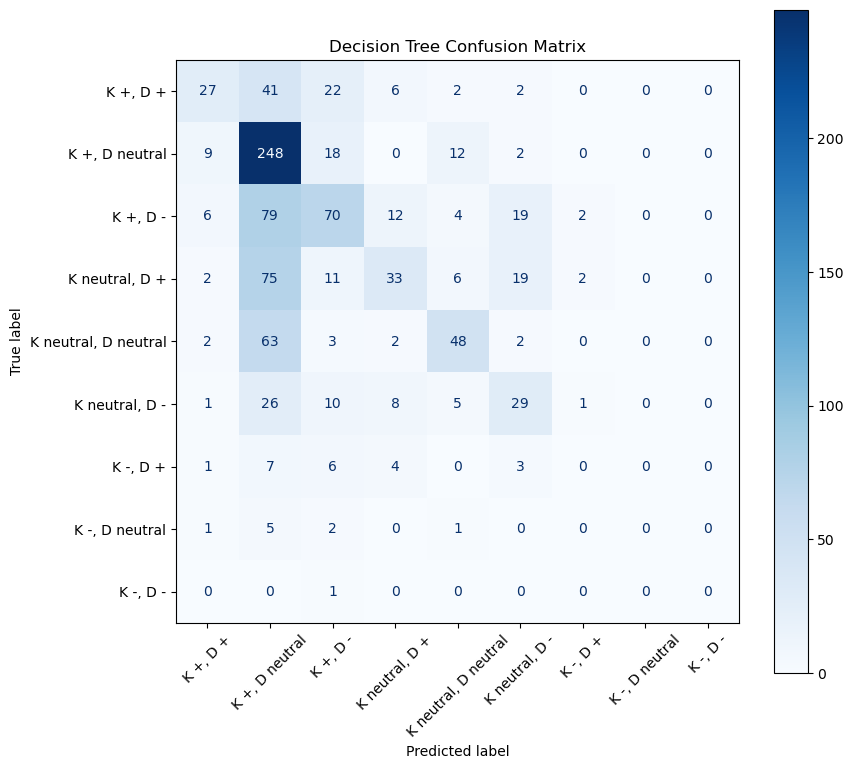

                      precision    recall  f1-score   support

            K +, D +       0.55      0.27      0.36       100
      K +, D neutral       0.46      0.86      0.60       289
            K +, D -       0.49      0.36      0.42       192
      K neutral, D +       0.51      0.22      0.31       148
K neutral, D neutral       0.62      0.40      0.48       120
      K neutral, D -       0.38      0.36      0.37        80
            K -, D +       0.00      0.00      0.00        21
      K -, D neutral       0.00      0.00      0.00         9
            K -, D -       0.00      0.00      0.00         1

            accuracy                           0.47       960
           macro avg       0.33      0.28      0.28       960
        weighted avg       0.48      0.47      0.44       960



In [51]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

splitpercentage = 0.1684
X_train, X_test, y_train, y_test = train_test_split(youtube_comment_texts,
                                                    youtube_comment_labels,
                                                    test_size=splitpercentage,
                                                    random_state=112)

#Creating the model
vec = CountVectorizer()
X = vec.fit_transform(X_train)
X_test_vec = vec.transform(X_test)

#looking at the accuract with depth
depth = 17
tree = DecisionTreeClassifier(max_depth=depth, random_state=5124)
tree.fit(X, y_train)

print(depth, round(tree.score(X, y_train), 3),
            round(tree.score(X_test_vec, y_test), 3))

y_pred = tree.predict(X_test_vec)

cm = confusion_matrix(y_test, y_pred, labels=all_labels)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=all_labels).plot(
    ax=ax, cmap='Blues', xticks_rotation=45
)
plt.title('Decision Tree Confusion Matrix')
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, labels=all_labels, zero_division=0))

960
960


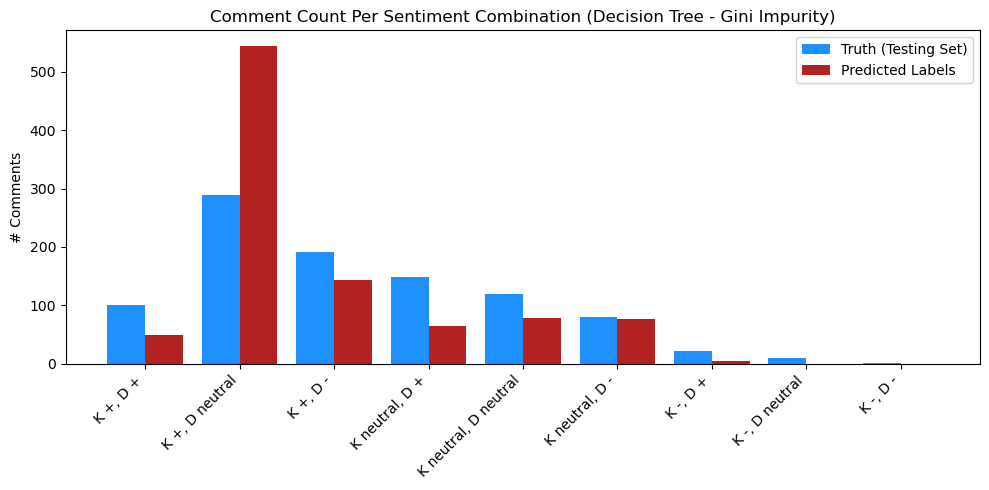

In [54]:
actual_counts = pd.Series(y_test).value_counts().reindex(all_labels, fill_value=0)
pred_counts =pd.Series(y_pred).value_counts().reindex(all_labels, fill_value=0)

print(np.sum(pd.Series(y_test).value_counts()))
print(np.sum(pd.Series(y_pred).value_counts()))

bar_width = 0.4
pos = np.arange(len(all_labels))

plt.figure(figsize=(10, 5))
plt.bar(pos - bar_width/2, actual_counts.values, width=bar_width, color='dodgerblue', label='Truth (Testing Set)')
plt.bar(pos + bar_width/2, pred_counts.values, width=bar_width, color='firebrick', label='Predicted Labels')
plt.xticks(pos, all_labels, rotation=45, ha='right')
plt.ylabel('# Comments')
plt.title('Comment Count Per Sentiment Combination (Decision Tree - Gini Impurity)')
plt.legend()
plt.tight_layout()
plt.show()

I'm making an example like Dr. O's for decision trees that show the difference between the entropy and gini impurity methods of measuring the goodness of fit for a tree

C:\Users\namth\AppData\Local\Temp\ipykernel_9496\1617853415.py:6: RuntimeWarning: divide by zero encountered in log2
  entropy = -(p * np.log2(p)) - ((1-p)*np.log2(1-p))
C:\Users\namth\AppData\Local\Temp\ipykernel_9496\1617853415.py:6: RuntimeWarning: invalid value encountered in multiply
  entropy = -(p * np.log2(p)) - ((1-p)*np.log2(1-p))


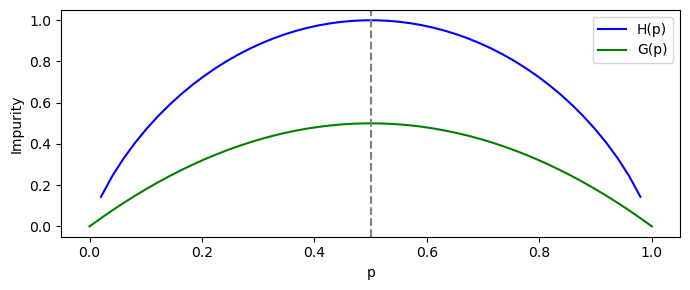

In [6]:
import numpy as np
import matplotlib.pyplot as plt

p = np.linspace(0, 1, num=50, endpoint=True)

entropy = -(p * np.log2(p)) - ((1-p)*np.log2(1-p))
gini = 2*p*(1-p)

plt.figure(figsize=(7, 3))
plt.plot(p, entropy, label='H(p)', c='blue')
plt.plot(p, gini, label='G(p)', c='green')
plt.axvline(x=0.5, ymin=0, ymax=1, ls='--', color='gray')
plt.xlabel('p')
plt.ylabel('Impurity')
plt.tight_layout()
plt.legend(loc='best')
plt.show()